# Experiment 6: Correlation and Linear Regression

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")
np.random.seed(42)

## Load data

In [2]:
data = load_diabetes(as_frame=True)
df = data.frame
print(df.shape)
display(df.head())

df.describe().round(3)

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,152.133
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,77.093
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138,25.000
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033,87.000
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001,140.500
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028,211.500
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136,346.000


## Correlation analysis

,coefficient,p_value
Pearson,0.586450,3.466006e-42
Spearman,0.561382,4.567024e-38
Kendall,0.391195,2.240476e-34


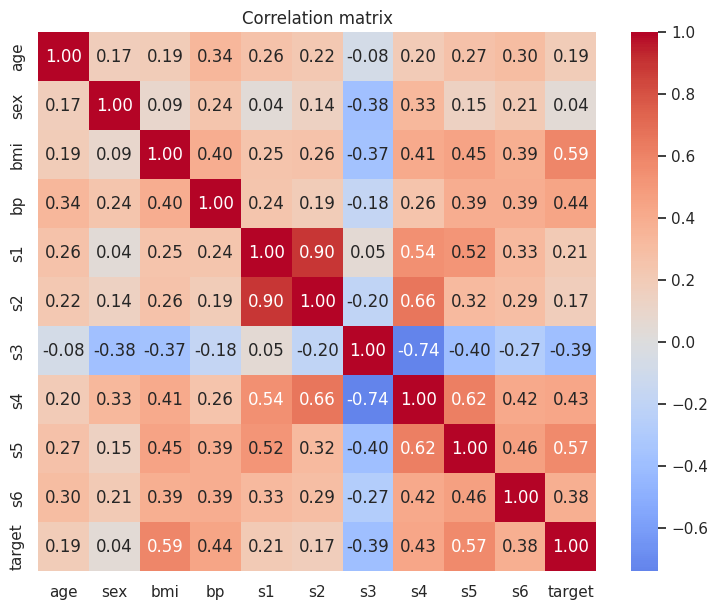

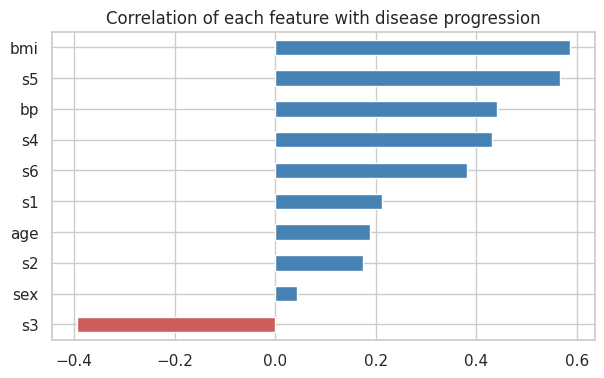

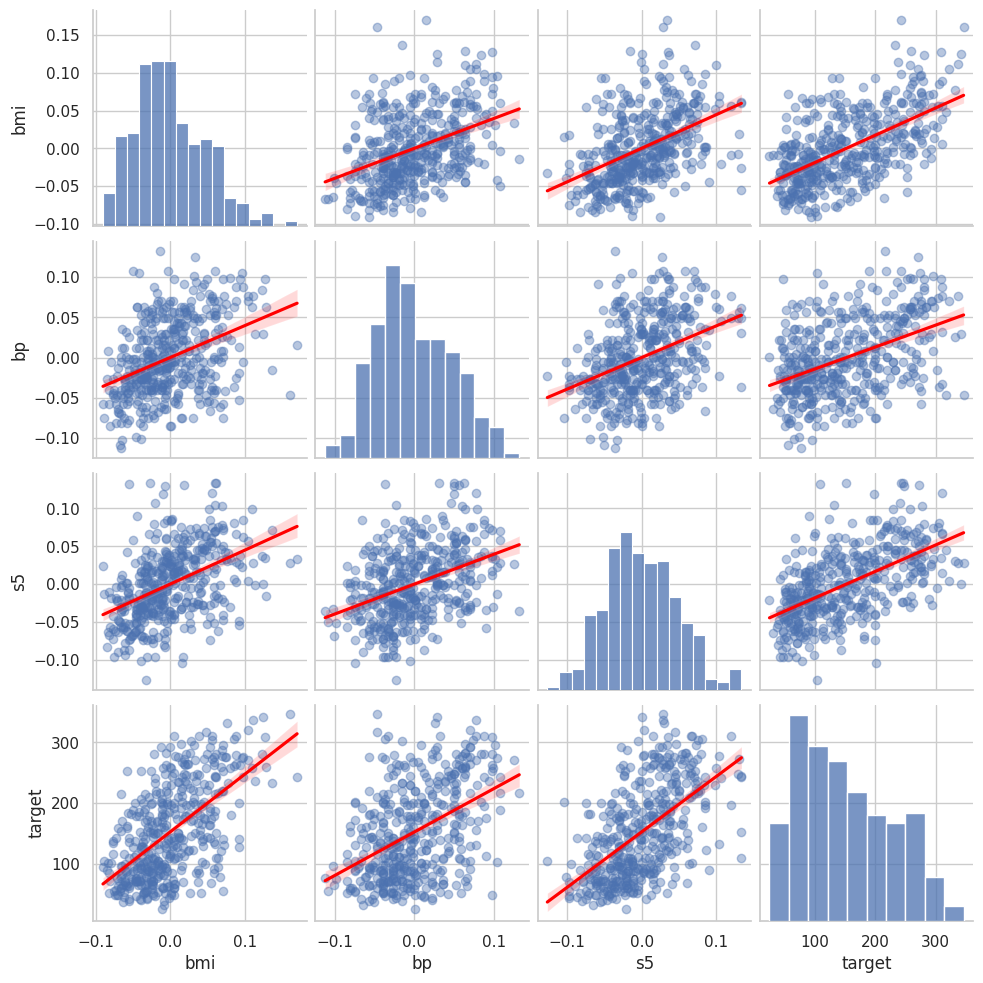

In [3]:
pearson_r, pearson_p = stats.pearsonr(df["bmi"], df["target"])
spearman_r, spearman_p = stats.spearmanr(df["bmi"], df["target"])
kendall_t, kendall_p = stats.kendalltau(df["bmi"], df["target"])
display(pd.DataFrame({
    "coefficient": [pearson_r, spearman_r, kendall_t],
    "p_value": [pearson_p, spearman_p, kendall_p],
}, index=["Pearson", "Spearman", "Kendall"]))

corr = df.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

target_corr = corr["target"].drop("target").sort_values()
plt.figure(figsize=(7, 4))
target_corr.plot(kind="barh", color=np.where(target_corr > 0, "steelblue", "indianred"))
plt.title("Correlation of each feature with disease progression")
plt.show()

sns.pairplot(df[["bmi", "bp", "s5", "target"]], kind="reg", plot_kws={"line_kws": {"color": "red"}, "scatter_kws": {"alpha": 0.4}})
plt.show()

## Simple linear regression (SciPy)

Slope = 949.4353
Intercept = 152.1335
r = 0.5865, R-squared = 0.3439
p-value = 3.466e-42, std error = 62.5151


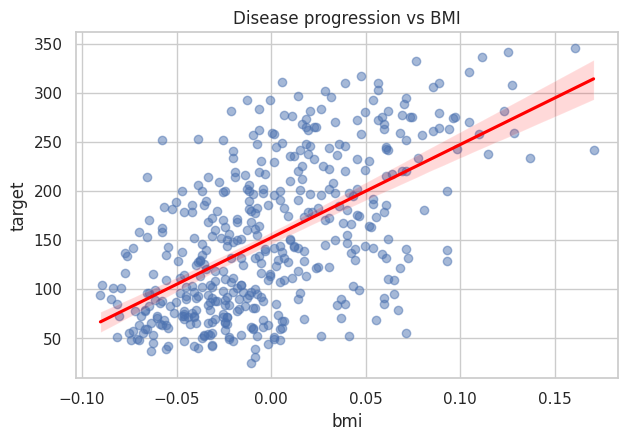

In [4]:
res = stats.linregress(df["bmi"], df["target"])
print(f"Slope = {res.slope:.4f}")
print(f"Intercept = {res.intercept:.4f}")
print(f"r = {res.rvalue:.4f}, R-squared = {res.rvalue**2:.4f}")
print(f"p-value = {res.pvalue:.3e}, std error = {res.stderr:.4f}")

plt.figure(figsize=(7, 4.5))
sns.regplot(data=df, x="bmi", y="target", scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
plt.title("Disease progression vs BMI")
plt.show()

## Simple linear regression (scikit-learn, train/test)

Intercept: 152.003 | Coefficient: [998.578]
R2   : 0.2334
MSE  : 4061.826
RMSE : 63.732
MAE  : 52.26


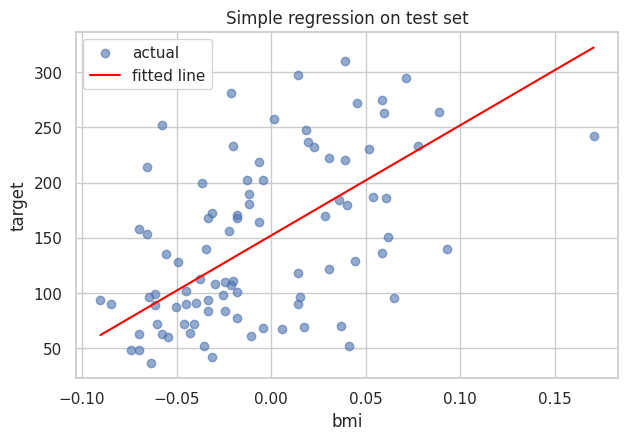

In [5]:
X = df[["bmi"]]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
slr = LinearRegression().fit(X_train, y_train)
print("Intercept:", slr.intercept_.round(3), "| Coefficient:", slr.coef_.round(3))

y_pred = slr.predict(X_test)
print("R2   :", round(r2_score(y_test, y_pred), 4))
print("MSE  :", round(mean_squared_error(y_test, y_pred), 3))
print("RMSE :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("MAE  :", round(mean_absolute_error(y_test, y_pred), 3))

plt.figure(figsize=(7, 4.5))
plt.scatter(X_test, y_test, alpha=0.6, label="actual")
order = np.argsort(X_test["bmi"].values)
plt.plot(X_test["bmi"].values[order], y_pred[order], color="red", label="fitted line")
plt.xlabel("bmi"); plt.ylabel("target"); plt.legend(); plt.title("Simple regression on test set")
plt.show()

## Multiple linear regression

Intercept: 151.346


s1    -931.489
sex   -241.964
age     37.904
s6      48.671
s3     163.420
s4     275.318
bp     347.704
s2     518.062
bmi    542.429
s5     736.199
dtype: float64

Train R2: 0.5279
Test R2 : 0.4526
RMSE    : 53.853
MAE     : 42.794
Adjusted R2: 0.3824
5-fold R2 scores: [0.4296 0.5226 0.4827 0.4265 0.5502]
Mean R2: 0.4823


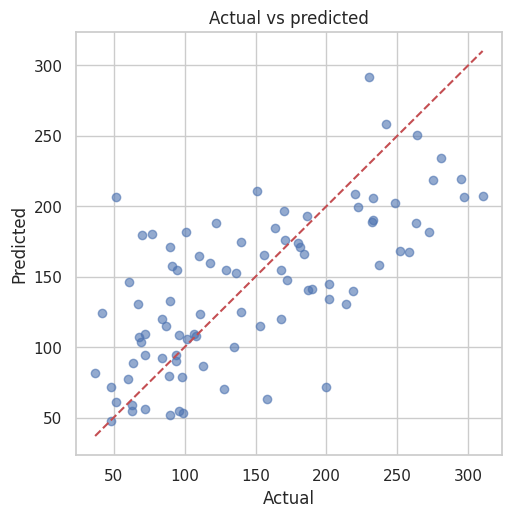

In [6]:
features = [c for c in df.columns if c != "target"]
X = df[features]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
mlr = LinearRegression().fit(X_train, y_train)
coef = pd.Series(mlr.coef_, index=features).sort_values()
print("Intercept:", round(mlr.intercept_, 3))
display(coef.round(3))

y_pred = mlr.predict(X_test)
print("Train R2:", round(mlr.score(X_train, y_train), 4))
print("Test R2 :", round(r2_score(y_test, y_pred), 4))
print("RMSE    :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("MAE     :", round(mean_absolute_error(y_test, y_pred), 3))
r2 = r2_score(y_test, y_pred)
n, k = X_test.shape
print("Adjusted R2:", round(1 - (1 - r2) * (n - 1) / (n - k - 1), 4))

cv = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print("5-fold R2 scores:", cv.round(4))
print("Mean R2:", cv.mean().round(4))

plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test, y_pred, alpha=0.6)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Actual vs predicted")
plt.show()

## Statistical summary of the model (statsmodels OLS)

In [7]:
X_sm = sm.add_constant(X)
ols = sm.OLS(y, X_sm).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.518
Model:                            OLS   Adj. R-squared:                  0.507
Method:                 Least Squares   F-statistic:                     46.27
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           3.83e-62
Time:                        18:34:56   Log-Likelihood:                -2386.0
No. Observations:                 442   AIC:                             4794.
Df Residuals:                     431   BIC:                             4839.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        152.1335      2.576     59.061      0.0

## Residual analysis and assumptions

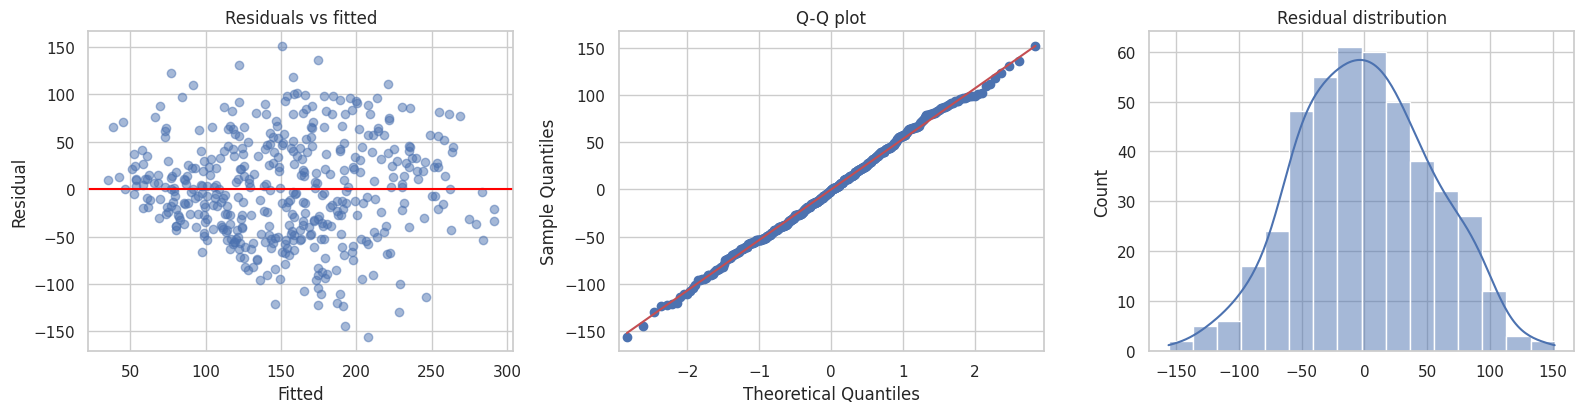

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9970648033327665), pvalue=np.float64(0.6161820926783175))
Durbin-Watson statistic  : 2.0285
Breusch-Pagan LM p-value : 0.0035


,feature,VIF
4,s1,59.20
5,s2,39.19
6,s3,15.40
8,s5,10.08
7,s4,8.89
2,bmi,1.51
9,s6,1.48
3,bp,1.46
1,sex,1.28
0,age,1.22


In [8]:
resid = ols.resid
fitted = ols.fittedvalues
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].scatter(fitted, resid, alpha=0.5); axes[0].axhline(0, color="red")
axes[0].set_xlabel("Fitted"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs fitted")
sm.qqplot(resid, line="s", ax=axes[1]); axes[1].set_title("Q-Q plot")
sns.histplot(resid, kde=True, ax=axes[2]); axes[2].set_title("Residual distribution")
plt.tight_layout()
plt.show()

print("Shapiro-Wilk on residuals:", stats.shapiro(resid))
print("Durbin-Watson statistic  :", round(durbin_watson(resid), 4))
bp = het_breuschpagan(resid, X_sm)
print("Breusch-Pagan LM p-value :", round(bp[1], 4))

vif = pd.DataFrame({"feature": X.columns, "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
vif.sort_values("VIF", ascending=False).round(2)

## Prediction on new data

In [9]:
new = pd.DataFrame([df[features].mean()])
new["bmi"] = 0.05
print("Predicted progression:", round(mlr.predict(new)[0], 2))

Predicted progression: 178.47
